Load datasets, including transactions_fraud_train.csv, infrastructure_metrics.csv, and application_logs.csv

Clean the data by handling missing values and standardizing data types

Explore distributions of key business KPIs, such as success rates and processing times

Analyze infrastructure metrics, including CPU utilization, memory usage, and error rates

Correlate transaction performance with infrastructure load
    
Visualize patterns to identify system bottlenecks and anomalies

In [1]:
# Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the requested data sets.
trns_fraud_df = pd.read_csv('/Users/raj/Desktop/CapStone/bankOps-platform/DataSets/transactions_fraud_train.csv')
infra_metrics_df = pd.read_csv('/Users/raj/Desktop/CapStone/bankOps-platform/DataSets/infrastructure_metrics.csv')
app_logs_df = pd.read_csv('/Users/raj/Desktop/CapStone/bankOps-platform/DataSets/application_logs.csv')

Lets check the size the size of each dataset loaded.

In [3]:
print(f"Length of Transaction Fraud Dataset is {len(trns_fraud_df)}")
print(f"Length of Infrastructure Metrics Dataset is {len(infra_metrics_df)}")
print(f"Length of Application Logs Dataset is {len(app_logs_df)}")

Length of Transaction Fraud Dataset is 4000
Length of Infrastructure Metrics Dataset is 10080
Length of Application Logs Dataset is 5000


In [4]:
# Print the head of the data sets loaded.
print('First 5 observations for Transaction Fraud Dataset is ...')
display(trns_fraud_df.head())
print('First 5 observations for Infrastructure Metric Dataset is ...')
display(infra_metrics_df.head())
print('First 5 observations for Application logs Dataset is ...')
display(app_logs_df.head())


First 5 observations for Transaction Fraud Dataset is ...


,transaction_id,customer_id,timestamp,transaction_type,amount,merchant_category,device_type,location,processing_time_ms,is_fraud
0,TXN0000006217,CUST001141,2025-09-11 18:10:33,UPI,2263.76,Education,Web_Mobile,Delhi,1250.51,0
1,TXN0000008782,CUST001598,2025-08-23 17:26:34,UPI,41978.43,Fuel,ATM,Delhi,1072.20,0
2,TXN0000022311,CUST004059,2025-10-05 01:52:37,IMPS,72791.10,Travel,Web_Desktop,Pune,908.33,0
3,TXN0000010022,CUST001835,2025-09-19 04:37:34,UPI,20349.39,Retail,Mobile_iOS,Mumbai,391.90,0
4,TXN0000027277,CUST004976,2025-08-16 00:53:38,RTGS,1428038.37,Healthcare,Mobile_Android,Chennai,796.37,0


First 5 observations for Infrastructure Metric Dataset is ...


,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,auth_success_rate,transaction_volume_per_hour,service_uptime
0,2025-10-20 00:00:00,42.82,36.96,25.62,168.08,0,99.46,99.20,99.71,108.99,99.47,4664,100.0
1,2025-10-20 00:01:00,36.99,33.99,25.53,179.73,2,98.45,98.28,99.29,100.00,98.96,4570,100.0
2,2025-10-20 00:02:00,40.99,33.33,34.22,167.39,0,99.80,99.93,99.81,102.10,98.60,4368,100.0
3,2025-10-20 00:03:00,37.98,32.66,30.48,146.32,3,98.08,99.09,99.18,100.00,99.28,4878,100.0
4,2025-10-20 00:04:00,44.44,33.69,26.14,155.62,1,97.09,99.66,99.36,135.61,99.04,3281,100.0


First 5 observations for Application logs Dataset is ...


,timestamp,log_level,log_message
0,2025-10-20 00:00:00,INFO,INFO: Transaction processed successfully. ID: ...
1,2025-10-20 00:01:00,ERROR,ERROR: NEFT transaction failed. Transaction ID...
2,2025-10-20 00:01:00,ERROR,ERROR: Database connection pool exhausted. Con...
3,2025-10-20 00:03:00,ERROR,ERROR: IMPS transaction failed. Transaction ID...
4,2025-10-20 00:03:00,WARNING,WARNING: Memory usage approaching threshold on...


Check if we have any null values or duplicate values in the datasets.

In [5]:
print(f'Null Values present in Transaction Fraud Dataset:')
display(trns_fraud_df.isna().sum())
print(f'Null values present in Infrastructure Metrics Dataset:')
display(infra_metrics_df.isna().sum())
print(f'Null values present in Application Logs Dataset:')
display(app_logs_df.isnull().sum())

Null Values present in Transaction Fraud Dataset:


transaction_id        0
customer_id           0
timestamp             0
transaction_type      0
amount                0
merchant_category     0
device_type           0
location              0
processing_time_ms    0
is_fraud              0
dtype: int64

Null values present in Infrastructure Metrics Dataset:


timestamp                             0
cpu_utilization                       0
memory_usage                          0
db_connection_pool_usage              0
network_throughput_mbps               0
application_error_rate                0
neft_success_rate                     0
imps_success_rate                     0
rtgs_success_rate                     0
avg_transaction_processing_time_ms    0
auth_success_rate                     0
transaction_volume_per_hour           0
service_uptime                        0
dtype: int64

Null values present in Application Logs Dataset:


timestamp      0
log_level      0
log_message    0
dtype: int64

From the above output cell, we see that there are no null/empty values present in the data sets. Now lets check for any duplicated values.

In [6]:
print(f'Duplicate Values present in Transaction Fraud Dataset:')
display(trns_fraud_df.duplicated().sum())
print(f'Duplicate values present in Infrastructure Metrics Dataset:')
display(infra_metrics_df.duplicated().sum())
print(f'Duplicate values present in Application Logs Dataset:')
display(app_logs_df.duplicated().sum())

Duplicate Values present in Transaction Fraud Dataset:


0

Duplicate values present in Infrastructure Metrics Dataset:


0

Duplicate values present in Application Logs Dataset:


9

From the above output cell, we cann see only Application Logs data set has duplicate values and also this is less than 5% of the size of the data set so we can ignore and move on to the next step.

Now lets proceed and look at the datatypes for the features present in the datasets.

In [7]:
trns_fraud_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      4000 non-null   object 
 1   customer_id         4000 non-null   object 
 2   timestamp           4000 non-null   object 
 3   transaction_type    4000 non-null   object 
 4   amount              4000 non-null   float64
 5   merchant_category   4000 non-null   object 
 6   device_type         4000 non-null   object 
 7   location            4000 non-null   object 
 8   processing_time_ms  4000 non-null   float64
 9   is_fraud            4000 non-null   int64  
dtypes: float64(2), int64(1), object(7)
memory usage: 312.6+ KB


In [8]:
infra_metrics_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10080 entries, 0 to 10079
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   timestamp                           10080 non-null  object 
 1   cpu_utilization                     10080 non-null  float64
 2   memory_usage                        10080 non-null  float64
 3   db_connection_pool_usage            10080 non-null  float64
 4   network_throughput_mbps             10080 non-null  float64
 5   application_error_rate              10080 non-null  int64  
 6   neft_success_rate                   10080 non-null  float64
 7   imps_success_rate                   10080 non-null  float64
 8   rtgs_success_rate                   10080 non-null  float64
 9   avg_transaction_processing_time_ms  10080 non-null  float64
 10  auth_success_rate                   10080 non-null  float64
 11  transaction_volume_per_hour         10080

<Figure size 2000x1000 with 0 Axes>

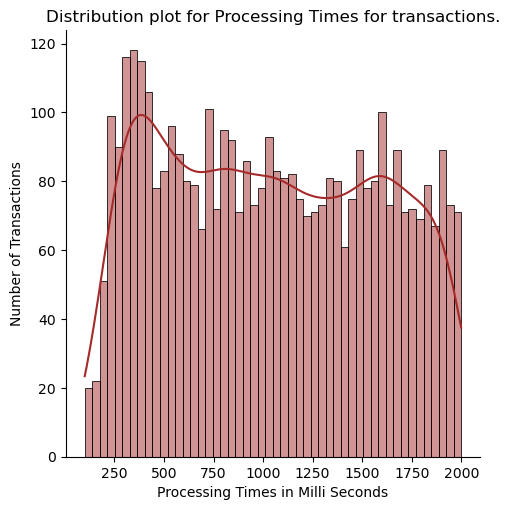

In [9]:
plt.figure(figsize=(20,10))

sns.displot(
    data=trns_fraud_df,
    x="processing_time_ms",
    bins=50,
    kde=True,
    color='#A52A2A',
)

plt.title("Distribution plot for Processing Times for transactions.")
plt.xlabel("Processing Times in Milli Seconds")
plt.ylabel("Number of Transactions")

plt.show()

From the above distribution plot, we can say that the processing times are distributed from 100 to 2000 ms, while the transactions that are present on the left side of plot have less processing times, we should be concerned about the transactions that are present on the right side of plot which have higher processing times of around 1500 to 2000 ms, we should further analyze these transactions and check if processing times are effected by transaction type, device type, merchant or location. Lets proceed and plot box plots for processing times versus each of the feature.

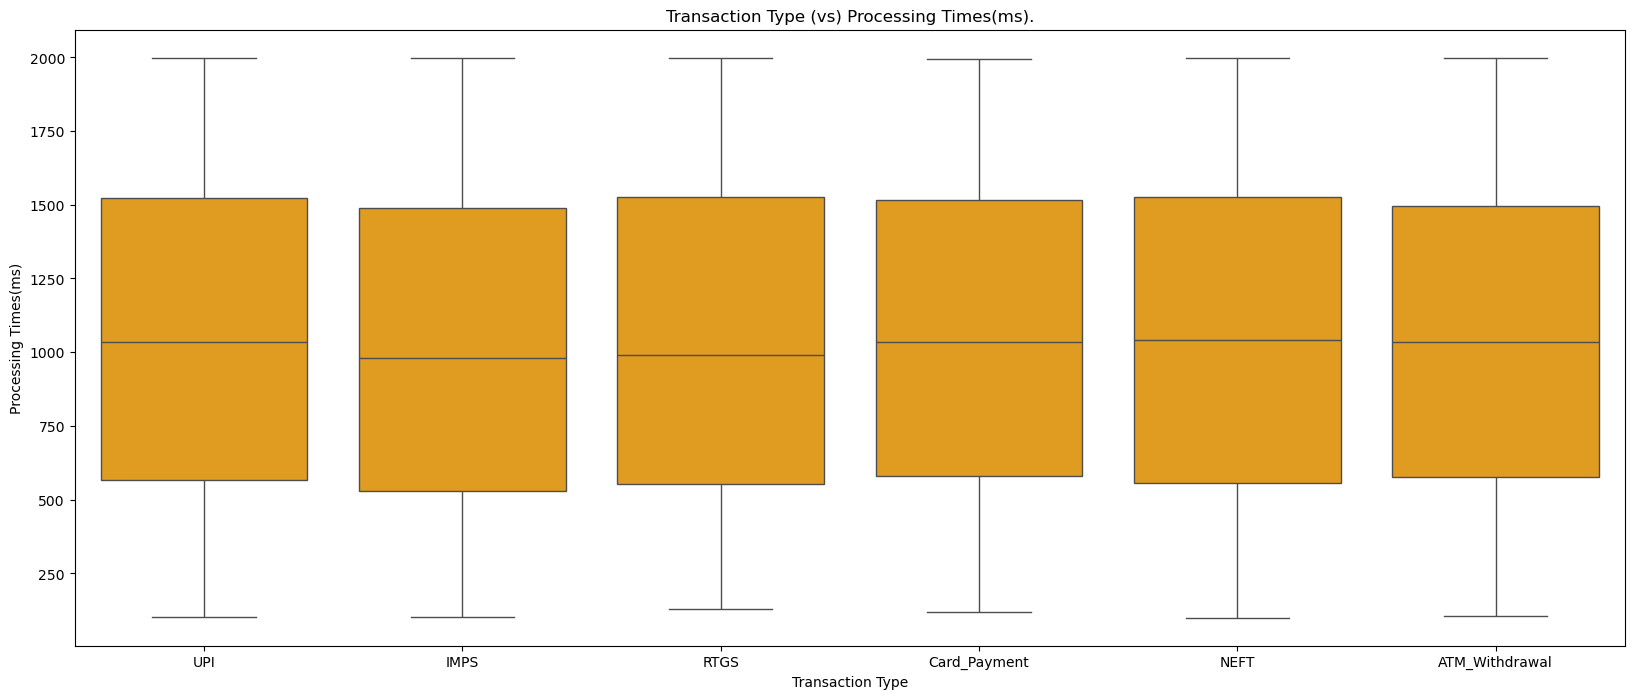

In [10]:
plt.figure(figsize=(20,8))

sns.boxplot(
    data=trns_fraud_df,
    x='transaction_type',
    y='processing_time_ms',
    color='orange'
)

plt.title('Transaction Type (vs) Processing Times(ms).')
plt.xlabel('Transaction Type')
plt.ylabel('Processing Times(ms)')

plt.show()


From the above box plot, we can see that all the transaction types don't have an effect on the processing times as we can see almost all transaction types have a maximum processing times of around 2000 ms and an median processing times of 1000ms.

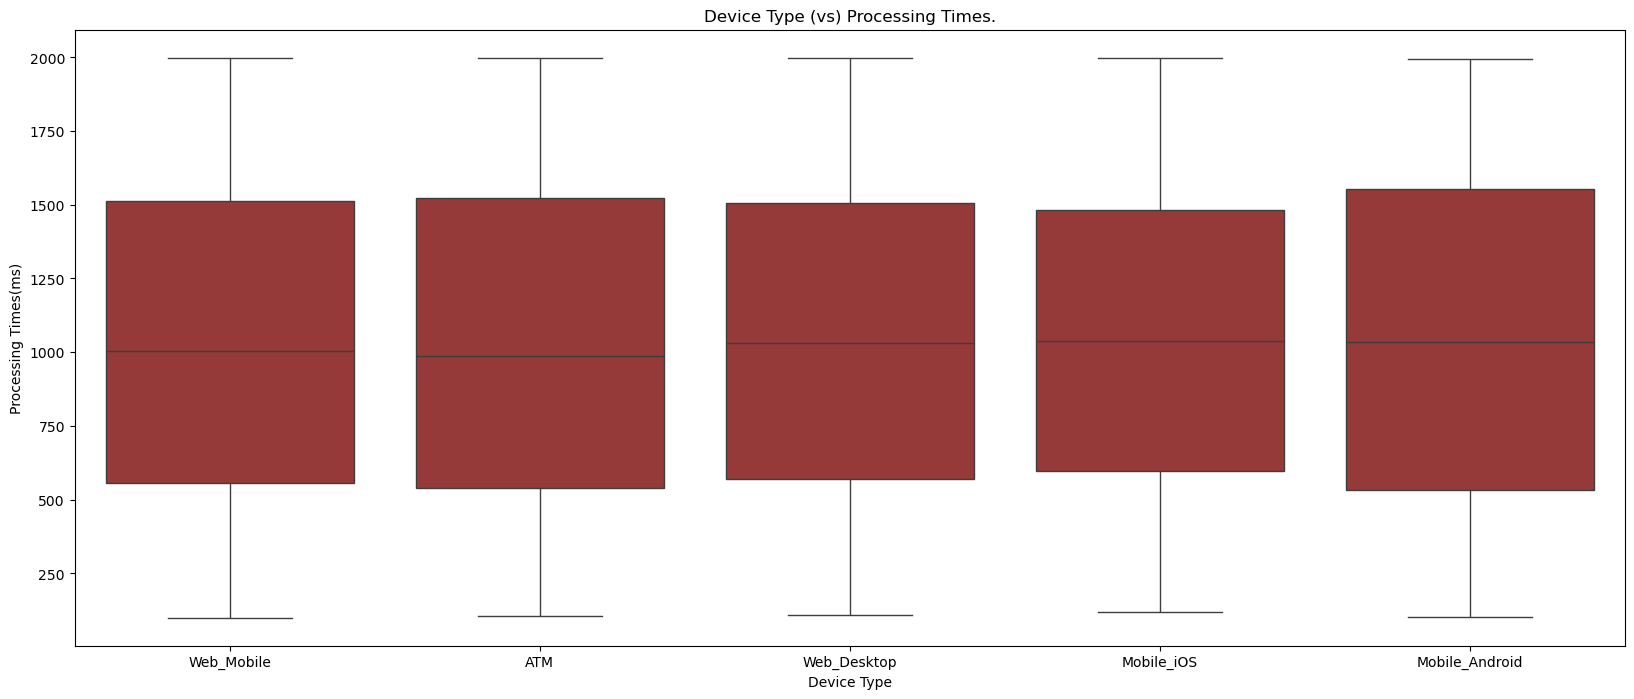

In [11]:
plt.figure(figsize=(20,8))

sns.boxplot(
    data=trns_fraud_df,
    x='device_type',
    y='processing_time_ms',
    color='brown'
)

plt.title('Device Type (vs) Processing Times.')
plt.xlabel('Device Type')
plt.ylabel('Processing Times(ms)')

plt.show()


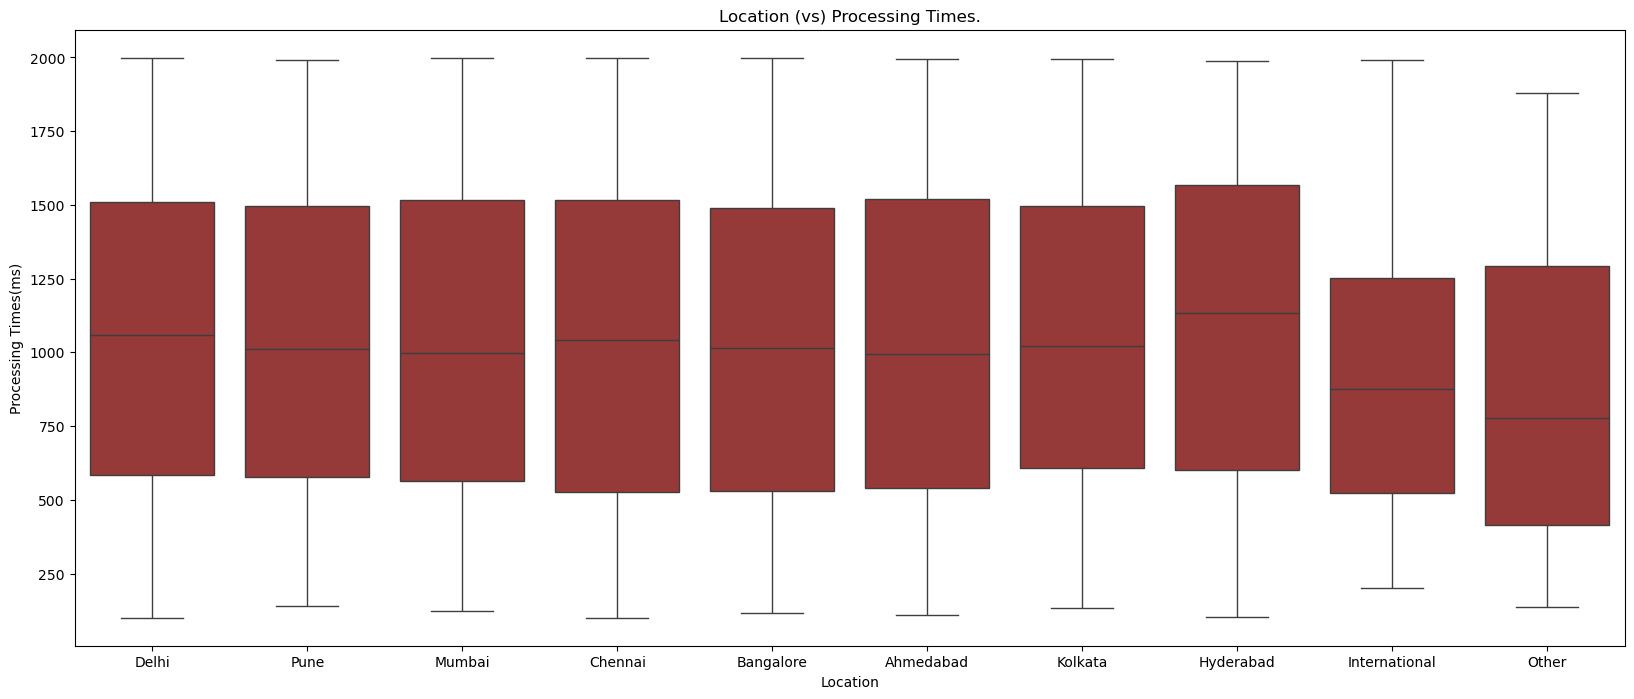

In [12]:
plt.figure(figsize=(20,8))

sns.boxplot(
    data=trns_fraud_df,
    x='location',
    y='processing_time_ms',
    color='brown'
)

plt.title('Location (vs) Processing Times.')
plt.xlabel('Location')
plt.ylabel('Processing Times(ms)')

plt.show()


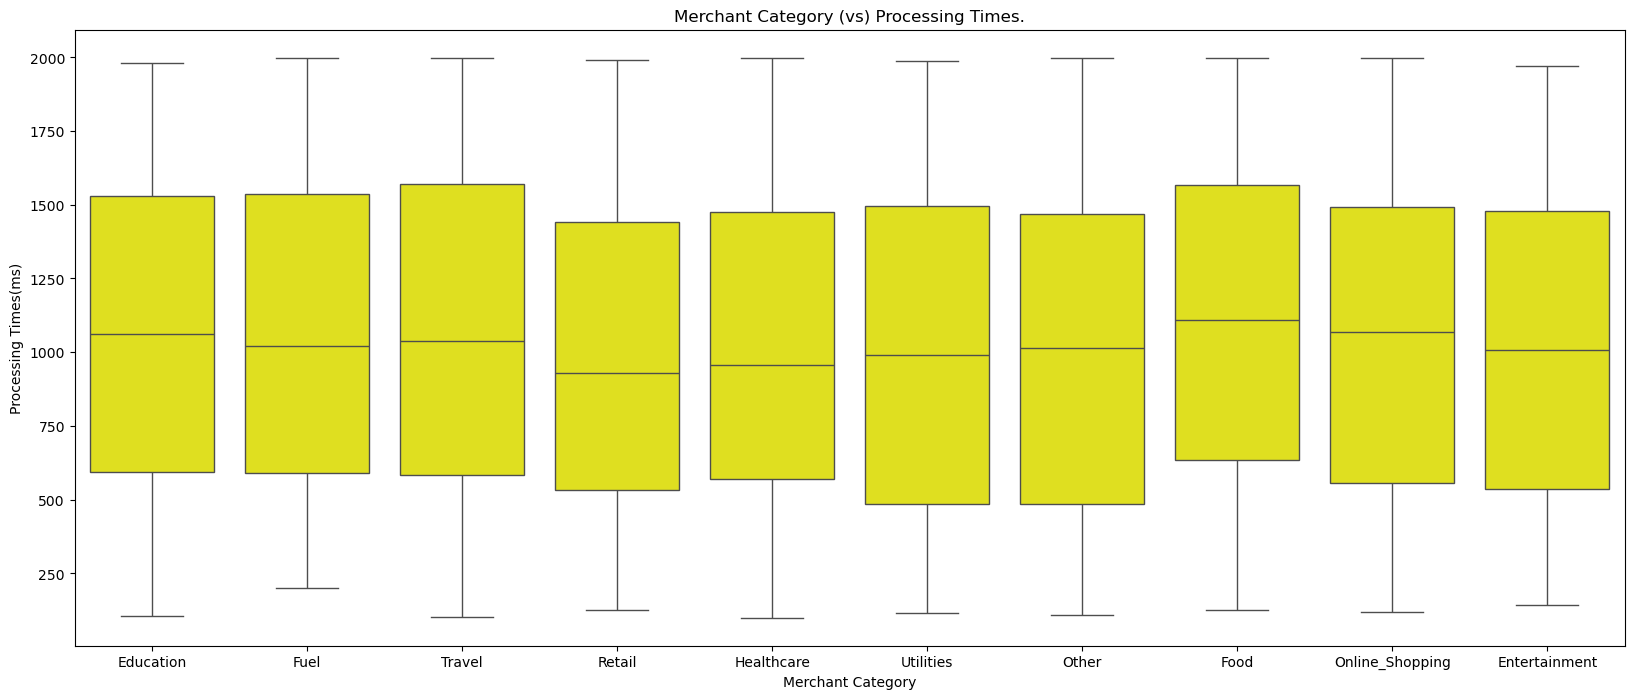

In [13]:


plt.figure(figsize=(20,8))

sns.boxplot(
    data=trns_fraud_df,
    x='merchant_category',
    y='processing_time_ms',
    color='yellow'
)

plt.title('Merchant Category (vs) Processing Times.')
plt.xlabel('Merchant Category')
plt.ylabel('Processing Times(ms)')

plt.show()

neft_success_rate		

<Figure size 2000x1000 with 0 Axes>

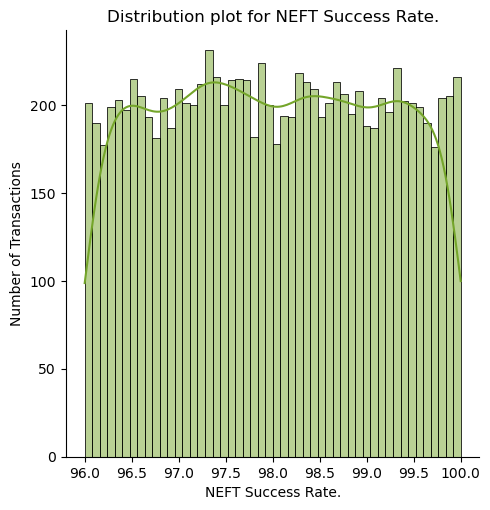

In [14]:
plt.figure(figsize=(20,10))

sns.displot(
    data=infra_metrics_df,
    x="neft_success_rate",
    bins=50,
    kde=True,
    color="#74A52A",
)

plt.title("Distribution plot for NEFT Success Rate.")
plt.xlabel("NEFT Success Rate.")
plt.ylabel("Number of Transactions")

plt.show()

<Figure size 2000x1000 with 0 Axes>

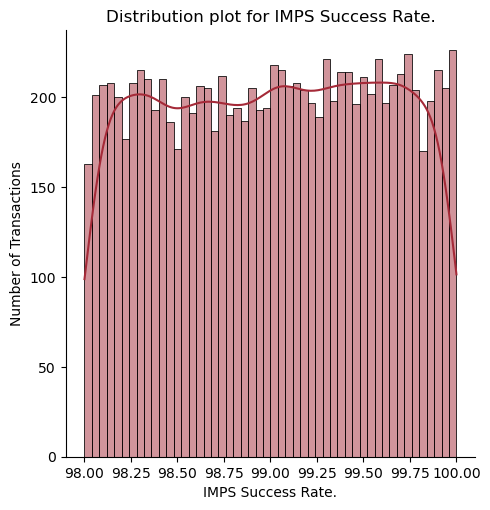

In [15]:
plt.figure(figsize=(20,10))

sns.displot(
    data=infra_metrics_df,
    x="imps_success_rate",
    bins=50,
    kde=True,
    color="#A52A38",
)

plt.title("Distribution plot for IMPS Success Rate.")
plt.xlabel("IMPS Success Rate.")
plt.ylabel("Number of Transactions")

plt.show()

<Figure size 2000x1000 with 0 Axes>

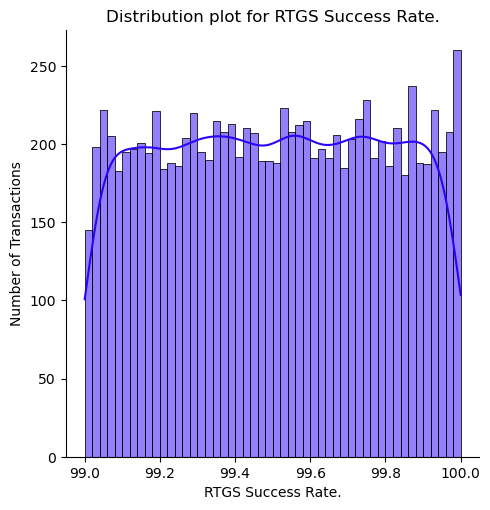

In [16]:
plt.figure(figsize=(20,10))

sns.displot(
    data=infra_metrics_df,
    x="rtgs_success_rate",
    bins=50,
    kde=True,
    color="#2C03F8",
)

plt.title("Distribution plot for RTGS Success Rate.")
plt.xlabel("RTGS Success Rate.")
plt.ylabel("Number of Transactions")


plt.show()

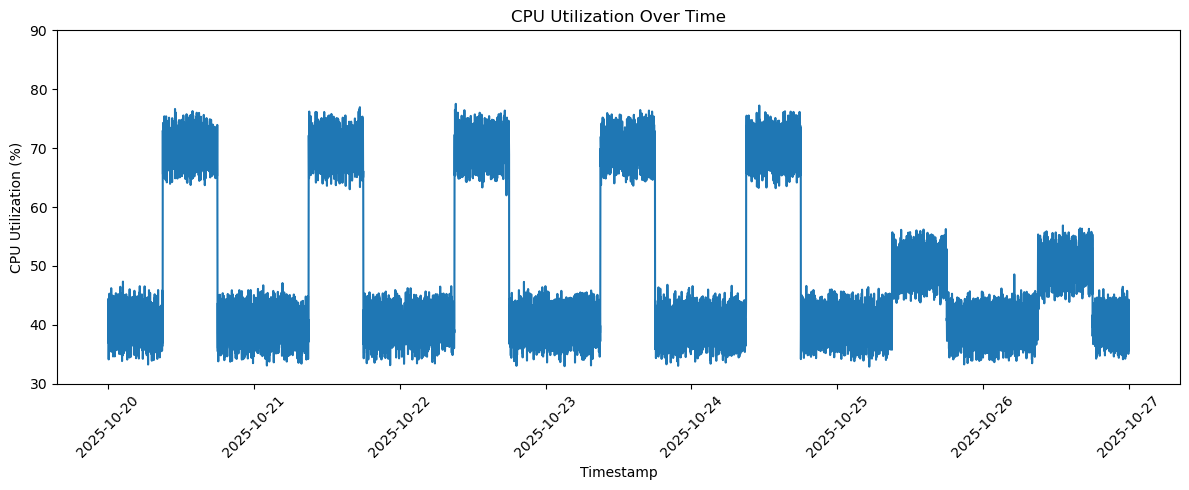

In [17]:
infra_metrics_df["timestamp"] = pd.to_datetime(infra_metrics_df["timestamp"])

# CPU utilization over time
plt.figure(figsize=(12, 5))
sns.lineplot(data=infra_metrics_df, x="timestamp", y="cpu_utilization")

plt.title("CPU Utilization Over Time")
plt.xlabel("Timestamp")
plt.ylabel("CPU Utilization (%)")
plt.yticks([30,40,50,60,70,80,90])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

From the above plot, we can see that the CPU Utilization reached a maximum of around 77%, we can say that the CPU Utilization is moderately high but not alarmingly high. One intersting observation till Oct 24th, we can see that the CPU utilization is reaching a maximum value of around 77%, however from Oct 25th we can see that the CPU utilization is moderate and is around 55% max. We need to identify any potential issues or CRON jobs that were running till Oct 24th which would result in unusual spikes.

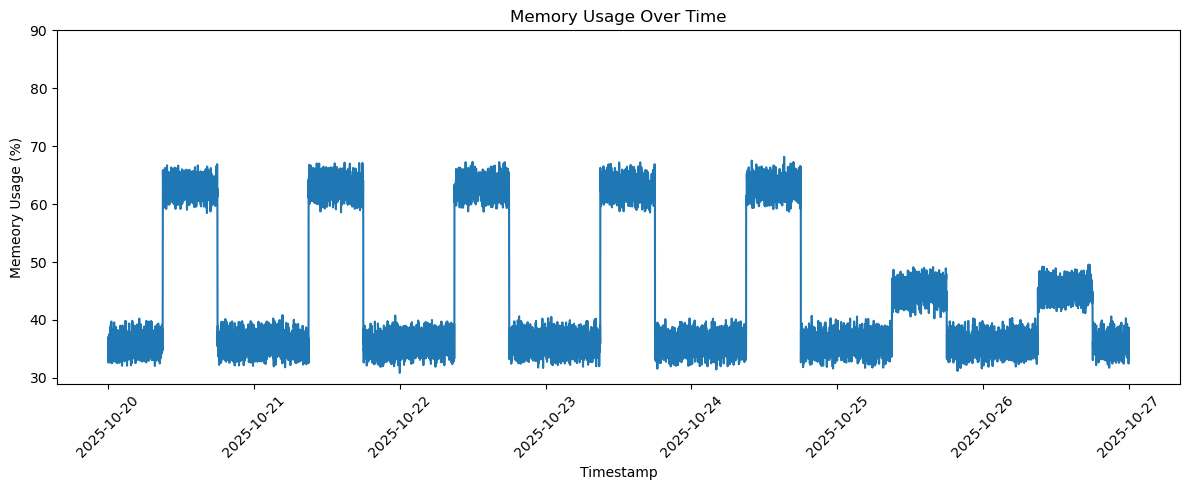

In [18]:
infra_metrics_df["timestamp"] = pd.to_datetime(infra_metrics_df["timestamp"])

# Memory Usage over time
plt.figure(figsize=(12, 5))
sns.lineplot(data=infra_metrics_df, x="timestamp", y="memory_usage")

plt.title("Memory Usage Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Memeory Usage (%)")
plt.yticks([30,40,50,60,70,80,90])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

For memory usage as well, its a similar story. We need to identify what exactly is the cause of spikes, is it increase in the transaction volume or if something is wrong with infrastructure, if so what was done to fix the spikes.

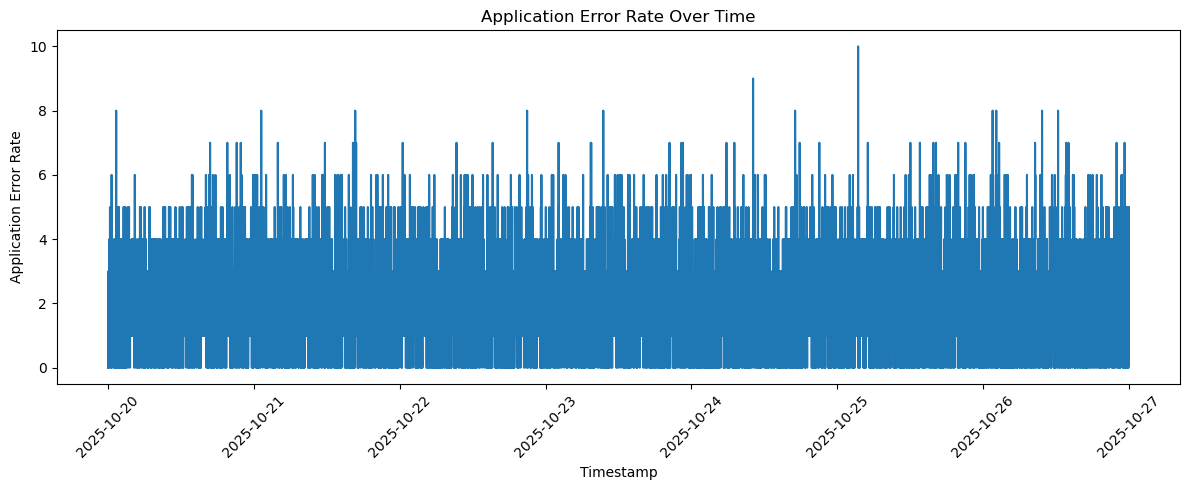

In [19]:

infra_metrics_df["timestamp"] = pd.to_datetime(infra_metrics_df["timestamp"])

# Memory Usage over time
plt.figure(figsize=(12, 5))
sns.lineplot(data=infra_metrics_df, x="timestamp", y="application_error_rate")

plt.title("Application Error Rate Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Application Error Rate")
#plt.yticks([30,40,50,60,70,80,90])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
print("Transaction date range:")
print(trns_fraud_df["timestamp"].min(),
      trns_fraud_df["timestamp"].max())

print("\nInfrastructure date range:")
print(infra_metrics_df["timestamp"].min(),
      infra_metrics_df["timestamp"].max())

Transaction date range:
2025-08-05 01:57:34 2025-11-03 01:49:35

Infrastructure date range:
2025-10-20 00:00:00 2025-10-26 23:59:00


Since we have Over lap between transactions and infrasture for Oct 20 through Oct 26, we can filter the transactions between those dates and use that filtered data to establish correlation between transactions and infrastructure.

In [21]:
start_date = "2025-10-20"
end_date = "2025-10-27"

filtered_transactions_df = trns_fraud_df[
    (trns_fraud_df["timestamp"] >= start_date) &
    (trns_fraud_df["timestamp"] < end_date)
].copy()

In [22]:
len(filtered_transactions_df)

313

In [23]:
filtered_transactions_df["timestamp"] = pd.to_datetime(filtered_transactions_df["timestamp"])

We have 313 transactions around the time frame mentioned, we can go ahead and use the transactions that are available and see if there is any correlation between transaction performance and infrastructure load. For us to achieve this, first we need to merge the datasets.

In [24]:
# Create a minute-level timestamp
filtered_transactions_df["minute"] = (
    filtered_transactions_df["timestamp"].dt.floor("min")
)

infra_metrics_df["minute"] = (
    infra_metrics_df["timestamp"].dt.floor("min")
)

# Aggregate transactions by minute
transaction_minute = (
    filtered_transactions_df.groupby("minute")
    .agg(
        avg_processing_time=(
            "processing_time_ms", "mean"
        ),
        median_processing_time=(
            "processing_time_ms", "median"
        ),
        transaction_count=(
            "transaction_id", "count"
        )
    )
    .reset_index()
)

# Aggregate infrastructure metrics by minute
infrastructure_minute = (
    infra_metrics_df.groupby("minute")
    .agg({
        "cpu_utilization": "mean",
        "memory_usage": "mean",
        "db_connection_pool_usage": "mean",
        "network_throughput_mbps": "mean",
        "application_error_rate": "mean",
        "transaction_volume_per_hour": "mean",
        "neft_success_rate": "mean",
        "imps_success_rate": "mean",
        "rtgs_success_rate": "mean"
    })
    .reset_index()
)

display(transaction_minute.head())

,minute,avg_processing_time,median_processing_time,transaction_count
0,2025-10-20 00:02:00,517.90,517.90,1
1,2025-10-20 01:43:00,1894.04,1894.04,1
2,2025-10-20 02:09:00,1859.97,1859.97,1
3,2025-10-20 02:21:00,1915.87,1915.87,1
4,2025-10-20 02:22:00,617.33,617.33,1


In [25]:
merged_df = pd.merge(
    transaction_minute,
    infrastructure_minute,
    on="minute",
    how="inner"
)

display(merged_df.head())
print("Merged records:", len(merged_df))

,minute,avg_processing_time,median_processing_time,transaction_count,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,transaction_volume_per_hour,neft_success_rate,imps_success_rate,rtgs_success_rate
0,2025-10-20 00:02:00,517.90,517.90,1,40.99,33.33,34.22,167.39,0.0,4368.0,99.80,99.93,99.81
1,2025-10-20 01:43:00,1894.04,1894.04,1,42.64,34.57,27.40,211.04,5.0,4390.0,98.18,98.01,99.32
2,2025-10-20 02:09:00,1859.97,1859.97,1,43.36,33.65,28.52,188.58,3.0,4631.0,96.49,98.39,99.89
3,2025-10-20 02:21:00,1915.87,1915.87,1,38.22,34.41,39.10,147.72,4.0,4308.0,97.68,98.52,99.73
4,2025-10-20 02:22:00,617.33,617.33,1,39.93,39.05,34.46,186.42,0.0,4046.0,96.60,98.45,99.25


Merged records: 311


In [26]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   minute                       311 non-null    datetime64[ns]
 1   avg_processing_time          311 non-null    float64       
 2   median_processing_time       311 non-null    float64       
 3   transaction_count            311 non-null    int64         
 4   cpu_utilization              311 non-null    float64       
 5   memory_usage                 311 non-null    float64       
 6   db_connection_pool_usage     311 non-null    float64       
 7   network_throughput_mbps      311 non-null    float64       
 8   application_error_rate       311 non-null    float64       
 9   transaction_volume_per_hour  311 non-null    float64       
 10  neft_success_rate            311 non-null    float64       
 11  imps_success_rate            311 non-null    

In [27]:
correlation_columns = [
    "avg_processing_time",
    "transaction_count",
    "cpu_utilization",
    "memory_usage",
    "db_connection_pool_usage",
    "network_throughput_mbps",
    "application_error_rate"
]

correlation_matrix = merged_df[
    correlation_columns
].corr(method="pearson")

display(correlation_matrix)

,avg_processing_time,transaction_count,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate
avg_processing_time,1.000000,0.049991,-0.050901,-0.036019,-0.076174,0.004539,0.117667
transaction_count,0.049991,1.000000,0.027950,0.033556,0.030262,0.012325,0.169041
cpu_utilization,-0.050901,0.027950,1.000000,0.963105,0.876075,0.885417,0.054270
memory_usage,-0.036019,0.033556,0.963105,1.000000,0.865840,0.899803,0.044696
db_connection_pool_usage,-0.076174,0.030262,0.876075,0.865840,1.000000,0.796227,-0.042213
network_throughput_mbps,0.004539,0.012325,0.885417,0.899803,0.796227,1.000000,0.019849
application_error_rate,0.117667,0.169041,0.054270,0.044696,-0.042213,0.019849,1.000000


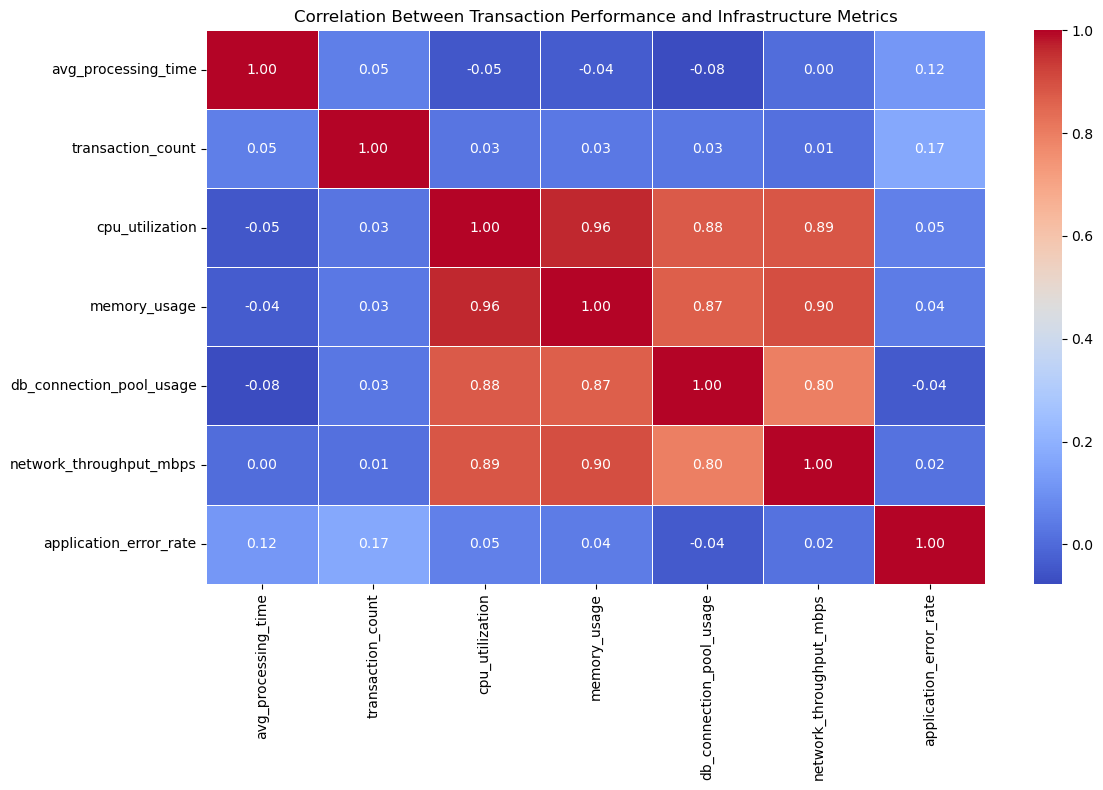

In [28]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Between Transaction Performance "
    "and Infrastructure Metrics"
)

plt.tight_layout()
plt.show()


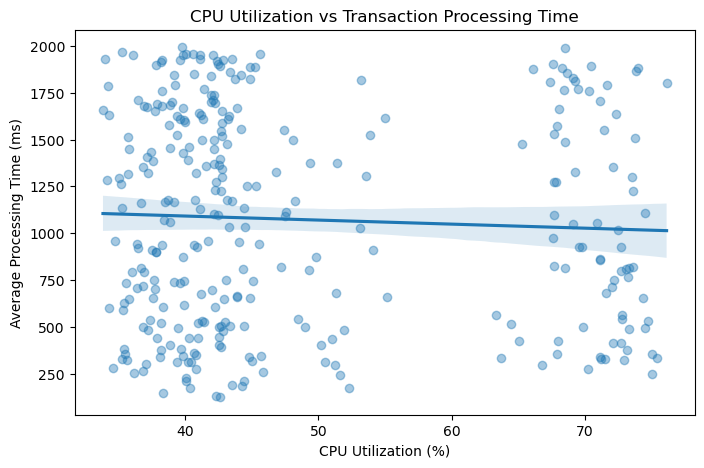

In [29]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=merged_df,
    x="cpu_utilization",
    y="avg_processing_time",
    scatter_kws={"alpha": 0.4}
)

plt.title("CPU Utilization vs Transaction Processing Time")
plt.xlabel("CPU Utilization (%)")
plt.ylabel("Average Processing Time (ms)")

plt.show()

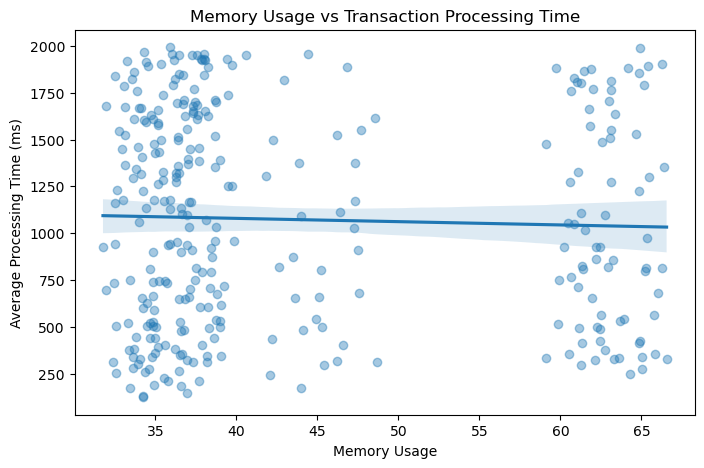

In [30]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=merged_df,
    x="memory_usage",
    y="avg_processing_time",
    scatter_kws={"alpha": 0.4}
)

plt.title("Memory Usage vs Transaction Processing Time")
plt.xlabel("Memory Usage")
plt.ylabel("Average Processing Time (ms)")

plt.show()

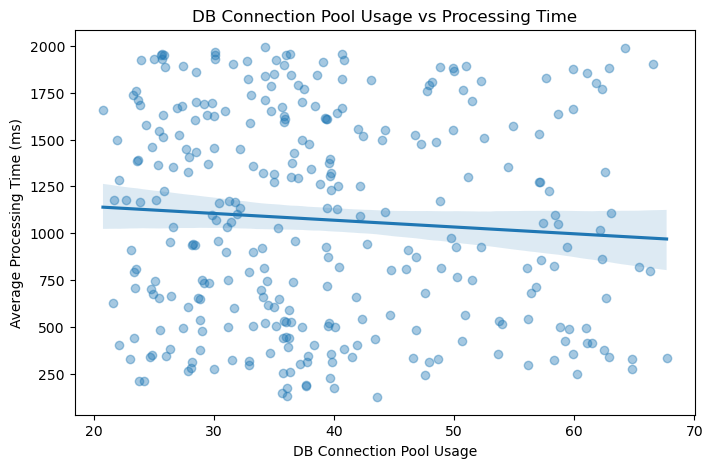

In [31]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=merged_df,
    x="db_connection_pool_usage",
    y="avg_processing_time",
    scatter_kws={"alpha": 0.4}
)

plt.title("DB Connection Pool Usage vs Processing Time")
plt.xlabel("DB Connection Pool Usage")
plt.ylabel("Average Processing Time (ms)")

plt.show()

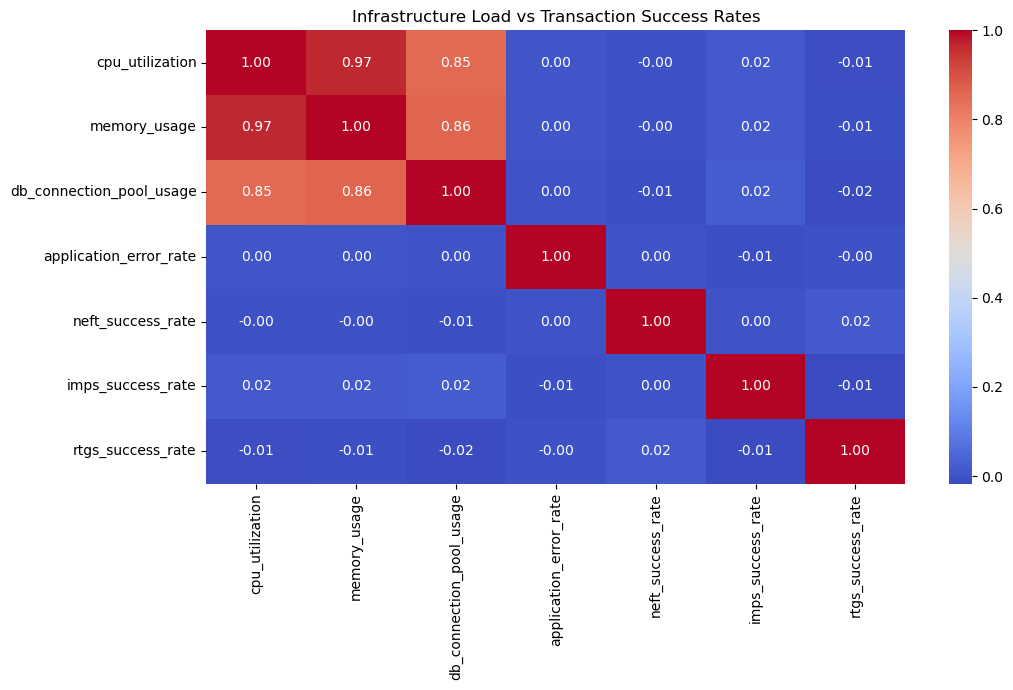

In [32]:
success_columns = [
    "cpu_utilization",
    "memory_usage",
    "db_connection_pool_usage",
    "application_error_rate",
    "neft_success_rate",
    "imps_success_rate",
    "rtgs_success_rate"
]

success_corr = infra_metrics_df[
    success_columns
].corr()

plt.figure(figsize=(11, 7))

sns.heatmap(
    success_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Infrastructure Load vs Transaction Success Rates")
plt.tight_layout()
plt.show()

With the limited transactions that we have in between Oct 20 through Oct 26, I dont see very low correalation for CPU Utlization, Memory and DB Connection Pool Usage to transaction average processing times. 

From the previous plots, we can infer that there are spikes in CPU Utilization, Memory and DB Connection Pool. Till 24th all these parameters are spiking at the same time and then the utilization goes and this is a pattern for an entire week. From Oct 25th all these parameters are well below the threshhold of aorund 50%.